# Predicting the "true OFF" MDS-UPDRS Part III score

*ENS Challenge Data #159 · SU-AS 2026 · final configuration **v11***

For every visit, the challenge asks for the patient's latent **"true OFF" MDS-UPDRS Part III
motor score** (0–132): the score the patient would show after a complete drug washout. No column
of the data holds it. A visit carries a score on medication (`on`), a score after an incomplete
washout (`off`), or both, and both are noisy, *multiplicative* views of the target. The metric is
the mean squared error (MSE).

| evaluation of v11 | MSE |
|---|---|
| public leaderboard | **4.1202** |
| private leaderboard | **6.0332** |
| 5-fold patient-grouped cross-validation, all training patients | not run for v11 |
| frozen 15% holdout | not read for v11 (section 6 says why) |

**What running it does.** The notebook fetches the code and checks the environment (section 0),
loads the data (2), builds the feature chain (3), trains the final model on every training
patient (4), then predicts the test set and writes the submission (5). On the machine that
produced our upload, the file it writes is the one we uploaded, byte for byte; section 5 checks
that. Sections 6 and 7 summarise how the model was chosen and what it does not do. A full run
takes about half an hour on an 8-core laptop CPU; the last cell prints the measured time.

## 0. Code and environment

The model lives in the `pdchallenge` Python package (some eleven thousand lines in 49 files), kept in the
GitHub repository [`luc6987/su-as-2026-pd`](https://github.com/luc6987/su-as-2026-pd) rather
than pasted here. The notebook drives the package and explains what each part does; no modelling
code is duplicated, so the two cannot drift apart.

**What you need**

1. **Python 3.12 or later** and Jupyter (any front end that runs a `.ipynb` will do).
2. **The challenge data.** Download `X_train_6ZIKlTY.csv`, `y_train_lXj6X5y.csv` and
   `X_test_oiZ2ukx.csv` from the [challenge page](https://challengedata.ens.fr/participants/challenges/159/)
   and put them, under these names, in a folder `data/` next to this notebook. The data are not
   redistributed with the code.
3. **Internet access on the first run.** The next two cells download the tagged release of the
   code into a folder next to the notebook, then `pip install` the exact library versions we
   used into the Python that runs this notebook. Use a fresh virtual or conda environment if
   you do not want your own packages changed.

**Optional switches** (environment variables; every default is the full run):

| variable | effect |
|---|---|
| `PD_DATA_DIR` | folder holding the three CSVs (default: `data/` next to the notebook, then `data/` in the code folder) |
| `PD_CODE_DIR` | use an existing checkout of the repository instead of downloading the release |
| `PD_OUTPUT_DIR` | where the submission is written (default: `output/` next to the notebook) |
| `PD_NB_INSTALL=0` | only report version differences; install nothing |
| `PD_NB_SMOKE=1` | a one-minute check: 300 training and 200 test patients, tiny models; the output is *not* the submission |
| `PD_NB_RUN_CV=1` | also run the 5-fold cross-validation in section 6 (about an hour more) |

Relative paths are read from the notebook's own folder.

In [1]:
# Section 0a — the code. Use a checkout if there is one, otherwise download the tagged release.
import io
import os
import shutil
import sys
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

CODE_REPOSITORY = "luc6987/su-as-2026-pd"
CODE_RELEASE = "v11"  # the git tag the outputs below were produced with
CODE_URL = os.environ.get(
    "PD_CODE_URL", f"https://github.com/{CODE_REPOSITORY}/archive/refs/tags/{CODE_RELEASE}.zip"
)


def shown(path: Path) -> str:
    """A path for printing, with the home directory abbreviated to `~`."""
    home, text = str(Path.home()), str(path)
    return "~" + text[len(home):] if text.startswith(home + os.sep) else text


def is_checkout(folder: Path) -> bool:
    return (folder / "pdchallenge" / "__init__.py").is_file()


def find_checkout() -> Path | None:
    """`PD_CODE_DIR` if it is set; otherwise the notebook's folder or any folder above it."""
    if os.environ.get("PD_CODE_DIR"):
        folder = Path(os.environ["PD_CODE_DIR"]).expanduser().resolve()
        if not is_checkout(folder):
            raise FileNotFoundError(f"PD_CODE_DIR={folder} holds no pdchallenge/ package")
        return folder
    here = Path.cwd().resolve()
    return next((folder for folder in (here, *here.parents) if is_checkout(folder)), None)


def download_release(url: str, target: Path) -> None:
    """Unpack the release archive into `target`.

    GitHub wraps the tree in a single top-level folder (`su-as-2026-pd-11/` for the tag `v11`),
    so the archive is unpacked next to `target` first and that one folder is moved into place;
    an entry that would land outside it is refused before anything is written.
    """
    print(f"downloading {url}")
    try:
        with urllib.request.urlopen(url, timeout=300) as response:
            payload = response.read()
    except urllib.error.HTTPError as error:
        raise RuntimeError(
            f"could not download the code ({error.code} {error.reason}). If the repository is not "
            f"public, clone it with git (`git clone https://github.com/{CODE_REPOSITORY}`) and "
            "set PD_CODE_DIR to the clone."
        ) from error
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        names = archive.namelist()
        top = names[0].split("/")[0]
        if any(not name.startswith(top + "/") or ".." in name.split("/") for name in names):
            raise RuntimeError(f"unexpected layout in {url}")
        staging = target.with_name(target.name + ".partial")
        shutil.rmtree(staging, ignore_errors=True)
        archive.extractall(staging)
    (staging / top).rename(target)
    shutil.rmtree(staging)


ROOT = find_checkout()
if ROOT is not None:
    print(f"code: using the checkout at {shown(ROOT)}")
else:
    ROOT = Path.cwd().resolve() / f"su-as-2026-pd-{CODE_RELEASE}"
    if is_checkout(ROOT):
        print(f"code: release {CODE_RELEASE} already downloaded to {shown(ROOT)}")
    else:
        download_release(CODE_URL, ROOT)
        print(f"code: release {CODE_RELEASE} downloaded to {shown(ROOT)}")

# First on the import path, so this copy wins over any other `pdchallenge` that is installed.
sys.path[:] = [str(ROOT)] + [entry for entry in sys.path if entry != str(ROOT)]

code: using the checkout at ~/Library/Mobile Documents/com~apple~CloudDocs/X/MS2A/AS/data_challange/dist/su-as-2026-pd


In [2]:
# Section 0b — the environment: the exact versions of the run that wrote our upload.
import importlib
import platform
import subprocess
from importlib import metadata

PINNED = {
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1",
    "lightgbm": "4.7.0",
    "torch": "2.14.1",
    "matplotlib": "3.11.1",
    "PyYAML": "6.0.3",
}
MODULE_OF = {"scikit-learn": "sklearn", "PyYAML": "yaml"}
INSTALL = os.environ.get("PD_NB_INSTALL", "1") != "0"

if sys.version_info < (3, 12):
    raise RuntimeError(f"Python {platform.python_version()} found; the code needs Python 3.12+")


def installed_version(distribution: str) -> str | None:
    """The installed release, without a local label (PyTorch's `2.14.1+cpu` is `2.14.1`)."""
    try:
        return metadata.version(distribution).split("+")[0]
    except metadata.PackageNotFoundError:
        return None


def pip_install(requirements: list[str], extra: list[str]) -> None:
    """`pip install` into the Python running this notebook; print pip's last line, or its tail on failure."""
    print("pip install", " ".join([*requirements, *extra]))
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
         *requirements, *extra],
        capture_output=True, text=True,
    )
    lines = (result.stdout + result.stderr).strip().splitlines()
    if result.returncode != 0:
        print("\n".join(lines[-25:]))
        raise RuntimeError(f"pip install failed (exit code {result.returncode})")
    print(" ", lines[-1] if lines else "done")


differences = {
    name: installed_version(name)
    for name, version in PINNED.items()
    if installed_version(name) != version
}
if not differences:
    print("environment: all pinned versions are installed —",
          ", ".join(f"{name} {version}" for name, version in PINNED.items()))
else:
    for name, found in differences.items():
        print(f"  {name}: found {found or 'nothing'}, pinned {PINNED[name]}")
    if not INSTALL:
        print("PD_NB_INSTALL=0: nothing installed. Other versions run, but the submission may "
              "then differ from ours in the last digits.")
    else:
        others = [f"{name}=={PINNED[name]}" for name in differences if name != "torch"]
        if others:
            pip_install(others, [])
        if "torch" in differences:
            # The set models run on the CPU. On Linux the default wheel pulls in several GB of
            # CUDA libraries the notebook never uses, so the CPU-only build is fetched instead.
            index = (["--index-url", "https://download.pytorch.org/whl/cpu"]
                     if sys.platform.startswith("linux") else [])
            pip_install([f"torch=={PINNED['torch']}"], index)
        loaded = [name for name in differences if MODULE_OF.get(name, name) in sys.modules]
        if loaded:
            raise RuntimeError(f"{', '.join(loaded)} changed after being imported: restart the "
                               "kernel and run all cells again")
        importlib.invalidate_caches()  # so the imports below see the freshly installed packages
        print("environment: pinned versions installed")

environment: all pinned versions are installed — numpy 2.5.3, pandas 2.3.3, scipy 1.18.1, scikit-learn 1.9.1, xgboost 3.4.1, lightgbm 4.7.0, torch 2.14.1, matplotlib 3.11.1, PyYAML 6.0.3


## 1. Setup

Imports, the switches, and the folders the data are read from and the submission is written to.

In [3]:
# Section 1 — setup. Nothing here reads the data yet.

import copy
import hashlib
import json
import logging
import time
import warnings
from contextlib import contextmanager

import numpy as np
import pandas as pd

# The `neighbour` step appends one column at a time to a frame that ends up ~200 columns wide,
# and pandas warns about the fragmentation on every insertion (the training log of 06 October
# carried 2.7 MB of these lines). It is a performance hint, not a correctness problem, so that one
# warning class is silenced; everything else is shown as usual. Likewise matplotlib's note that
# the house style's "semibold" weight falls back to bold on this font.
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SMOKE = os.environ.get("PD_NB_SMOKE") == "1"
RUN_CV = os.environ.get("PD_NB_RUN_CV") == "1"

import lightgbm  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import sklearn  # noqa: E402
import xgboost  # noqa: E402

import pdchallenge  # noqa: E402
from pdchallenge.config import RunConfig  # noqa: E402
from pdchallenge.data.loading import imputed_age_mask, load_data  # noqa: E402
from pdchallenge.data.schema import FILES, PATIENT  # noqa: E402
from pdchallenge.evaluation.tta import predict_with_tta  # noqa: E402
from pdchallenge.features.pipeline import build_pipeline  # noqa: E402
from pdchallenge.models.registry import build, with_seed  # noqa: E402
from pdchallenge.viz import style  # noqa: E402

# The three set-model members need PyTorch. It is reported here rather than required, so the
# notebook still loads without it; the model fit in section 4 is where its absence would stop.
try:
    import torch
    TORCH_VERSION: str | None = torch.__version__
except ImportError:
    TORCH_VERSION = None

REQUIRED_FILES = [FILES["X_train"], FILES["y_train"], FILES["X_test"]]


def data_folder() -> Path:
    """The first candidate folder that holds all three challenge CSVs."""
    if os.environ.get("PD_DATA_DIR"):
        candidates = [Path(os.environ["PD_DATA_DIR"]).expanduser().resolve()]
    else:
        candidates = [Path.cwd().resolve() / "data", ROOT / "data"]
    for folder in candidates:
        if all((folder / name).is_file() for name in REQUIRED_FILES):
            return folder
    raise FileNotFoundError(
        f"the challenge data is missing: download {', '.join(REQUIRED_FILES)} from "
        "https://challengedata.ens.fr/participants/challenges/159/ and put them in "
        f"{' or '.join(shown(folder) for folder in candidates)}, or set PD_DATA_DIR"
    )


DATA_DIR = data_folder()
OUTPUT_DIR = Path(os.environ.get("PD_OUTPUT_DIR") or "output").expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# The house palette and rcParams. `headless=False` matters: it leaves the backend alone, so the
# figures render inline under Jupyter instead of being forced to a file-only one. The dpi is
# lowered from the house default afterwards, to keep the executed notebook small.
style.apply_style(headless=False)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "figure.figsize": (7.2, 4.0)})

TIMINGS: dict[str, float] = {}
START = time.perf_counter()


@contextmanager
def timed(label: str):
    """Record how long a block took, so the last cell can report where the time went."""
    begin = time.perf_counter()
    yield
    TIMINGS[label] = time.perf_counter() - begin


print("python", platform.python_version(), "·", platform.platform(terse=True),
      "·", os.cpu_count(), "cpus")
print("numpy", np.__version__, "· pandas", pd.__version__, "· scikit-learn", sklearn.__version__,
      "· xgboost", xgboost.__version__, "· lightgbm", lightgbm.__version__)
print("torch", TORCH_VERSION if TORCH_VERSION else "not installed — the set models need it")
print("pdchallenge from", shown(Path(pdchallenge.__file__).parent))
print("data from", shown(DATA_DIR))
print("output to", shown(OUTPUT_DIR))
print("smoke mode", SMOKE, "· cross-validation", RUN_CV)

python 3.12.14 · macOS-27.0.1 · 8 cpus
numpy 2.5.3 · pandas 2.3.3 · scikit-learn 1.9.1 · xgboost 3.4.1 · lightgbm 4.7.0
torch 2.14.1
pdchallenge from ~/Library/Mobile Documents/com~apple~CloudDocs/X/MS2A/AS/data_challange/dist/su-as-2026-pd/pdchallenge
data from ~/Library/Mobile Documents/com~apple~CloudDocs/X/MS2A/AS/data_challange/data
output to ~/Library/Mobile Documents/com~apple~CloudDocs/X/MS2A/AS/data_challange/dist/su-as-2026-pd/notebook/output
smoke mode False · cross-validation False


## 2. Data

Load the three CSVs and look at them: size, missingness, and the invariants the rest of the
notebook relies on.

In [4]:
# Section 2 — the data, and the checks that say we loaded what we think we did.

with timed("data · load"):
    ds = load_data(data_dir=DATA_DIR, derived=False)

if SMOKE:
    # A patient subsample with a fixed seed, so a smoke run is reproducible: the whole path
    # runs in about a minute instead of half an hour. The submitted file is never produced this way.
    rng = np.random.default_rng(0)
    keep_train = ds.X_train[PATIENT].isin(
        rng.choice(np.unique(ds.train_patients), size=300, replace=False)
    ).to_numpy()
    keep_test = ds.X_test[PATIENT].isin(
        rng.choice(np.unique(ds.test_patients), size=200, replace=False)
    ).to_numpy()
    X_train = ds.X_train.loc[keep_train].reset_index(drop=True)
    X_test = ds.X_test.loc[keep_test].reset_index(drop=True)
    y = pd.Series(np.asarray(ds.y_train, dtype=float)[keep_train])
else:
    X_train = ds.X_train.reset_index(drop=True)
    X_test = ds.X_test
    y = pd.Series(np.asarray(ds.y_train, dtype=float))

per_train = X_train.groupby(PATIENT).size()
per_test = X_test.groupby(PATIENT).size()
overview = pd.DataFrame(
    {
        "visits": [len(X_train), len(X_test)],
        "patients": [X_train[PATIENT].nunique(), X_test[PATIENT].nunique()],
        "visits/patient q1": [per_train.quantile(0.25), per_test.quantile(0.25)],
        "visits/patient median": [per_train.median(), per_test.median()],
        "visits/patient q3": [per_train.quantile(0.75), per_test.quantile(0.75)],
        "visits/patient max": [per_train.max(), per_test.max()],
    },
    index=["train", "test"],
)
print(overview.to_string(float_format=lambda v: f"{v:g}"))
print(f"\ntarget: mean {y.mean():.2f} · sd {y.std():.2f} · min {y.min():g} · "
      f"median {y.median():g} · max {y.max():g}")

MISSING_COLUMNS = ["gene", "ledd", "time_since_intake_on", "time_since_intake_off",
                   "on", "off", "age_at_diagnosis"]
missing = pd.DataFrame(
    {
        "train": [X_train[c].isna().mean() for c in MISSING_COLUMNS],
        "test": [X_test[c].isna().mean() for c in MISSING_COLUMNS],
    },
    index=MISSING_COLUMNS,
).round(3)
print("\nshare missing, by column:")
print(missing.to_string())

for name, frame in (("train", X_train), ("test", X_test)):
    neither = int((frame["on"].isna() & frame["off"].isna()).sum())
    print(f"\n{name}: visits carrying neither an ON nor an OFF score: {neither}")
    assert neither == 0, "every visit carries at least one of on/off"

# X_test ships `age_at_diagnosis` complete while X_train is missing it for part of the cohort:
# the organiser filled the gap with one constant. `derived` reverts those rows to NaN, together
# with the time axis it was used to compute, so 5% of the test cohort is treated exactly like
# the same rows in training rather than given a fabricated time axis.
imputed = imputed_age_mask(X_test)
print(f"\nage_at_diagnosis imputed by the organiser: {int(imputed.sum())} test rows over "
      f"{X_test.loc[imputed, PATIENT].nunique()} patients — reverted to NaN by `derived`")

       visits  patients  visits/patient q1  visits/patient median  visits/patient q3  visits/patient max
train   55603      6971                  4                      7                 12                  12
test    23672      2988                  4                      7                 12                  12

target: mean 37.33 · sd 16.50 · min 0 · median 37.1 · max 109.5

share missing, by column:
                       train   test
gene                   0.323  0.328
ledd                   0.370  0.374
time_since_intake_on   0.467  0.473
time_since_intake_off  0.788  0.787
on                     0.300  0.307
off                    0.421  0.413
age_at_diagnosis       0.051  0.000

train: visits carrying neither an ON nor an OFF score: 0

test: visits carrying neither an ON nor an OFF score: 0

age_at_diagnosis imputed by the organiser: 1093 test rows over 146 patients — reverted to NaN by `derived`


**The observation model.** Both scores are one-sided, multiplicative views of the latent
target `T`. An OFF score is `T · m_v`, where `m_v` is a per-visit factor with mean 0.82 that
mostly falls below one (Figure 1): an incomplete washout hides part of the true OFF score. An
ON score is the same times `ρ(ledd, dt)`, the dose- and time-dependent response to medication.
Three facts follow, and the whole feature chain is built on them:

- **`m_v` is noise, not a patient trait.** Its split-half reliability across patients is
  0.048, so no per-patient correction can remove it; only more visits average it out.
- **Two scores of one visit are one observation.** They share the same `m_v` (the
  within-patient correlation of their deviations is 0.76).
- **The deficit is a ratio, not an offset.** Subtracting a constant leaves an error that falls
  with the score (slope −0.191 against the truth), so high scores are pulled down. The one
  patient-level constant is the ON amplitude (split-half reliability 0.841), and age at
  diagnosis and sex pin it.

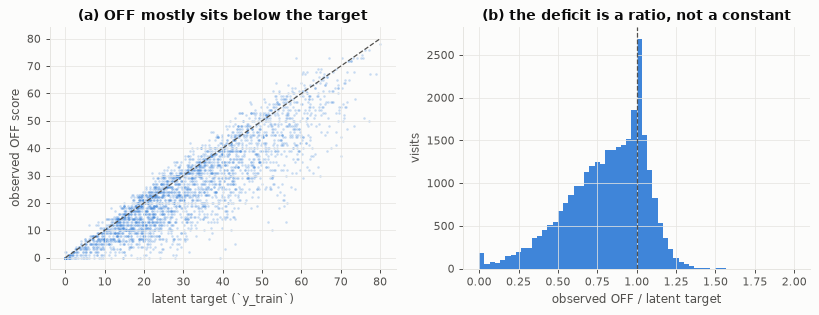

In [5]:
# Figure 1 — the observation model, seen in the data rather than asserted.
train_view = X_train.assign(target=y.to_numpy())
draw = np.random.default_rng(0).choice(len(train_view), size=min(5000, len(train_view)), replace=False)
sample = train_view.iloc[draw]
sample = sample[sample["off"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))

ax = axes[0]
ax.scatter(sample["target"], sample["off"], s=4, alpha=0.25, linewidths=0,
           color=style.PRED_COLOR)
edge = float(max(sample["target"].max(), sample["off"].max()))
ax.plot([0, edge], [0, edge], color=style.REF_COLOR, linewidth=1, linestyle="--")
ax.set_xlabel("latent target (`y_train`)")
ax.set_ylabel("observed OFF score")
ax.set_title("(a) OFF mostly sits below the target")

ax = axes[1]
with_off = train_view["off"].notna() & (train_view["target"] >= 10)
ax.hist((train_view.loc[with_off, "off"] / train_view.loc[with_off, "target"]).to_numpy(),
        bins=60, range=(0.0, 2.0), color=style.PRED_COLOR, alpha=0.9)
ax.axvline(1.0, color=style.REF_COLOR, linewidth=1, linestyle="--")
ax.set_xlabel("observed OFF / latent target")
ax.set_ylabel("visits")
ax.set_title("(b) the deficit is a ratio, not a constant")
fig.tight_layout()

## 3. Preprocessing: the feature chain

The chain is a list of transformers named in the configuration. Each step reads what the steps
before it wrote and appends its own columns. Every step declares whether its fitted state reads
the training target (`reads_target`) and whether a row's value depends only on that visit and
earlier ones (`causal`); the package's test suite checks both.

In [6]:
# Section 3 — read the configuration, then run the chain.

config_path = ROOT / "configs" / "consolidated_v11.yaml"
cfg = RunConfig.from_yaml(config_path)
print(f"config: {config_path.relative_to(ROOT)} · tag {cfg.tag}")
print("chain:")
for number, spec in enumerate(cfg.features, start=1):
    print(f"  {number:2d}. {spec if isinstance(spec, str) else json.dumps(spec, default=str)}")

pipeline = build_pipeline(cfg.features)
declarations = pd.DataFrame(
    [
        {
            "step": step.name,
            "class": type(step).__name__,
            "reads_target": type(step).reads_target,
            "causal": type(step).causal,
        }
        for step in pipeline.steps
    ]
)
print("\nstep declarations:")
print(declarations.to_string(index=False))

with timed("chain · fit_transform (train)"):
    X_train_f = pipeline.fit_transform(X_train, y)
print(f"\nfit_transform: {X_train_f.shape[0]:,} rows × {X_train_f.shape[1]:,} columns "
      f"in {TIMINGS['chain · fit_transform (train)']:.1f} s")

config: configs/consolidated_v11.yaml · tag consolidated-v11
chain:
   1. derived
   2. {"name": "debias", "use_patient_ldr": false}
   3. patient_curve
   4. on_ratio
   5. {"name": "pk_response", "prior": "aad_krig", "knn_pool": "fit+transform", "dt_slope": false, "effect_loading": true, "timing": true, "timing_tau": 0.4}
   6. {"name": "patient_aggregates", "obs_col": "obs_pk"}
   7. {"name": "envelope_curve", "value_col": "obs_pk", "weight_col": "obs_pk_weight", "tau": 0.95, "time_col": "age", "prior_scale": 0.25}
   8. {"name": "likelihood", "time_col": "age", "quadratic_min_obs": 6}
   9. {"name": "neighbour", "window": null}
  10. {"name": "floor", "obs_known_dt_only": true}
  11. {"name": "edge", "timing": true}

step declarations:
              step                   class  reads_target  causal
           derived         DerivedFeatures         False   False
            debias       DebiasTransformer          True    True
     patient_curve    PatientCurveFeatures          Tru

In [7]:
# The test set goes through the same loop `FeaturePipeline.transform` runs — every step's
# `transform`, in order — with the per-step bookkeeping spelled out. Only `fit` sees the
# target, so nothing learned here reads the test rows.

current = X_test
per_step: list[dict[str, object]] = []
for step in pipeline.steps:
    before = list(current.columns)
    with timed(f"chain · transform {step.name}"):
        current = step.transform(current)
    added = [column for column in current.columns if column not in before]
    per_step.append(
        {
            "step": step.name,
            "new columns": len(added),
            "first new columns": ", ".join(map(str, added[:3])),
            "seconds": round(TIMINGS[f"chain · transform {step.name}"], 1),
        }
    )
X_test_f = current

print(pd.DataFrame(per_step).to_string(index=False))
print(f"\ntest matrix: {X_test_f.shape[0]:,} rows × {X_test_f.shape[1]:,} columns")

              step  new columns                                             first new columns  seconds
           derived            6                          visit_idx, n_visits, age_first_visit      0.0
            debias            5                    pseudo_target, debias_source, bias_off_hat      0.0
     patient_curve            7                                  curve_a, curve_b, curve_pred      0.1
          on_ratio            5                                           rho_hat, on_eq, obs      0.0
       pk_response            9                                pk_amp_p, pk_amp_raw_p, pk_n_p      5.7
patient_aggregates            7                              obs_max_p, obs_q75_p, obs_mean_p      0.3
    envelope_curve            8                    env_level_log, env_slope_log, env_curv_log      0.6
        likelihood            7                    lik_level_log, lik_slope_log, lik_curv_log      1.4
         neighbour          116 obs_minus_lik_prev1, obs_minus_lik_next1,

What each step adds:

| step | what it adds |
|---|---|
| `derived` | per-visit bookkeeping: the time axis, the visit's index and count, has-ON/has-OFF flags; also reverts the organiser's imputed ages |
| `debias` | each observed score plus the population bias for its intake time (the patient-specific variant was measured and left off) |
| `patient_curve` | a shrunk linear curve through each patient's de-biased scores: an empirical-Bayes slope and intercept |
| `on_ratio` | the ON score divided by the fitted ratio `ρ̂(ledd, dt)`, which puts it on the OFF scale; fitted on visits with both scores, so it reads no target |
| `pk_response` | the per-patient part of that ratio: a prior from (age at diagnosis, sex), a patient-level absorption delay (−0.2609 on dev) and a per-visit effect loading (−0.1940) |
| `patient_aggregates` | the *upper end* of each patient's OFF-scale observations (maximum, upper quartile, this visit against them): what a one-sided factor leaves visible |
| `envelope_curve` | a per-patient log-scale quadratic fitted near the upper edge of the observations (moving it from the 80th to the 95th percentile was worth −1.5256); on the `age` axis, so the patients with no diagnosis date get a curve too (their error 21.86 → 9.68) |
| `likelihood` | the observation model written as a likelihood, with the empirical one-sided law of `m_v`, and the per-patient posterior it implies |
| `neighbour` | the values of the visit's neighbours in the same patient's trajectory (previous and next visit, gaps in years): −0.4981 |
| `floor` | a running lower bound from the patient's earlier scores, since the latent score never decreases (−0.4783); since v9 an ON score raises it only when its intake time is known, because converting it without one is about 3× noisier |
| `edge` | calibrated, covariate-dependent versions of that lower bound (quantile models); since v9 they also read when the patient's treatment started |

The numbers are paired dev MSE differences from the step's own experiment (negative is better).

## 4. Training the final model

The model has three layers. Its full specification is read from the configuration and printed
by the cell below; here is what the parts are.

**A blend of five members with fixed weights**, all fitted on the feature matrix of section 3:

| weight | member |
|---|---|
| 0.54 | five XGBoost boosters (seeds 0–4, depth 8, 1600 trees), averaged |
| 0.18 | the same five boosters on *level-normalised* inputs: every score-scale column is divided by a target-free patient scale, the booster fits y / scale with weight scale² (the squared error on the score scale) and predicts scale × f |
| 0.06 | a bidirectional GRU that reads a patient's visits as an age-ordered sequence (2 layers, level-normalised inputs) |
| 0.13 | the same GRU with 3 layers, *pre-trained* first: one visit of a patient is hidden down to its date and covariates and the network learns to reconstruct its scores from the other visits; only then is it trained on the target |
| 0.09 | the same pre-trained GRU, fed the `floor` and `edge` columns as v8 computed them (without the two switches v9 added), so the blend also carries the older chain's, differently wrong, errors |

**Scale test-time augmentation** (boosters only). The observations are multiplicative views of
the target, so scaling a visit's ON and OFF scores by s should scale its target by s. Each
booster therefore also predicts copies of the test rows with both scores multiplied by s, for
five values of s from 0.9 to 1.1, sent through the same fitted chain; each prediction is divided
by s and the five are averaged. Nothing is refitted and no target is read.

**Per-patient smoothing.** Most patients' true trajectories are cubics in age. Each patient's
blended predictions are projected onto such a curve (a quadratic plus a cubic term predicted
from its three coefficients, by a map learned on the training patients whose target is an
exact cubic). v11's one change over v10 comes next: in the generator, once a patient's curve
stops rising the score keeps growing by ×1.02 per visit, so the same rule is applied to the
fitted curve — walking the visits in age order, a value that does not rise above its
predecessor becomes the predecessor × 1.02. The result is averaged with the raw blend, three
parts to one.

In [8]:
# Section 4 — build the model from the config and fit it on the full training set.


def shrink_for_smoke(spec: dict) -> dict:
    """A copy of a model spec with every leaf shrunk, the nesting kept.

    Recursive because the final model is a blend whose first members are themselves ensembles:
    the outer weighted blend keeps its members and its weights, an inner mean ensemble over
    boosters keeps only its first, every booster drops to 60 trees, and every set model runs a
    single rep of a few epochs. Without the recursion the switch would never reach the boosters,
    which carry most of the fit time.
    """
    out = copy.deepcopy(spec)
    if out.get("name") == "gbm":
        out.setdefault("params", {})["n_estimators"] = 60
    elif out.get("name") in ("set_transformer", "visit_gru"):
        out["reps"] = 1
        # Three epochs, not two: on the smoke subsample two gives the learning-rate schedule
        # exactly 10 steps (five batches per epoch), the one length at which this torch build's
        # OneCycleLR divides by zero.
        out["epochs"] = 3
    for key, value in list(out.items()):
        if key == "base":
            out[key] = shrink_for_smoke(value)
        elif key == "members":
            members = [shrink_for_smoke(m) if isinstance(m, dict) else m for m in value]
            if out.get("method") == "mean" and members and all(
                isinstance(member, dict) and member.get("name") == "gbm" for member in members
            ):
                members = members[:1]
            out[key] = members
    if "weights" in out:
        # A weighted blend must keep one weight per member; the shrink must never desynchronise
        # the two lists.
        assert len(out["weights"]) == len(out["members"])
    return out


model_spec = copy.deepcopy(cfg.model)
if SMOKE:
    model_spec = shrink_for_smoke(model_spec)

print("model spec (read from the config; only the smoke switch edits it):")
print(json.dumps(model_spec, indent=2, default=str))

model = build(with_seed(model_spec, cfg.model_seed))
with timed("model · fit"):
    model.fit(X_train_f, y, groups=X_train[PATIENT].to_numpy())
print(f"\nfitted in {TIMINGS['model · fit']:.1f} s")

model spec (read from the config; only the smoke switch edits it):
{
  "name": "smoothed",
  "deg": 2,
  "w": 0.75,
  "time_col": "age",
  "family": "pinned_cubic",
  "continuation": "g2",
  "base": {
    "name": "ensemble",
    "method": "weighted",
    "weights": [
      0.54,
      0.18,
      0.06,
      0.13,
      0.09
    ],
    "members": [
      {
        "name": "ensemble",
        "method": "mean",
        "members": [
          {
            "name": "gbm",
            "seed": 0,
            "tta": true,
            "params": {
              "n_estimators": 1600,
              "learning_rate": 0.025,
              "max_depth": 8,
              "min_child_weight": 5,
              "subsample": 0.8,
              "colsample_bytree": 0.8
            }
          },
          {
            "name": "gbm",
            "seed": 1,
            "tta": true,
            "params": {
              "n_estimators": 1600,
              "learning_rate": 0.025,
              "max_depth": 8,
  

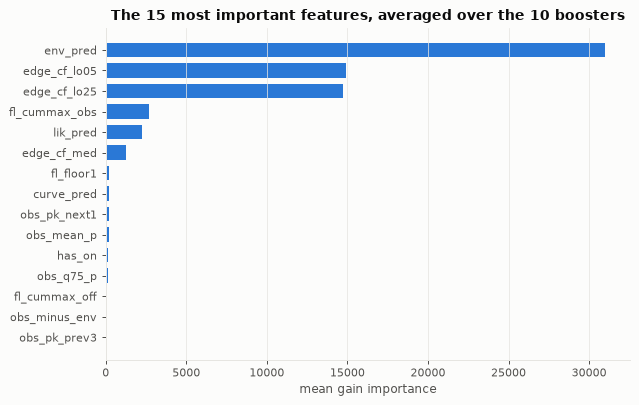

In [9]:
# Figure 2 — which features the boosters lean on: mean gain importance across members.


def importance_members(node) -> list:
    """Every fitted member that can report gain importance, walking nested ensembles.

    The fitted model is a `smoothed` wrapper whose `base_` is the weighted five-member blend; the
    boosters sit one level deeper, inside its two mean ensembles. The GRU members have no
    `feature_importance`, so they are skipped and the average runs over the ten boosters.
    """
    if hasattr(node, "feature_importance"):
        return [node]
    found: list = []
    for member in getattr(node, "members_", []):
        found.extend(importance_members(member))
    return found


boosters = importance_members(model.base_)
importances = pd.concat(
    [member.feature_importance(X_train_f) for member in boosters], axis=1
).mean(axis=1)
top = importances.sort_values(ascending=False).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.barh([str(name) for name in top.index], top.to_numpy(), color=style.PRED_COLOR, height=0.72)
ax.set_xlabel("mean gain importance")
ax.set_title(f"The 15 most important features, averaged over the {len(boosters)} boosters")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## 5. Predictions and the reproduction check

Prediction sends the test rows through the fitted chain once and, because the configuration
carries `tta_scales`, also sends the scaled copies the boosters average over (section 4); the
GRU members predict only the unscaled rows. Two details guard against a silently wrong file:
the predictions are paired with the test rows **by their `Index` label**, and the written file
is read back and re-checked. The writer is the one `pdchallenge/cli.py` uses, copied rather than
imported because importing that module selects a matplotlib backend, which would stop the
figures from rendering under Jupyter; the SHA-256 check below confirms the two paths agree.

In [10]:
# Section 5 — predict, write the submission, and verify it.


def write_submission(path: Path, index, target) -> pd.DataFrame:
    """Write `Index,target` and re-read it, exactly as `pdchallenge/cli.py` does."""
    idx = np.asarray(index)
    if isinstance(target, pd.Series):
        missing_index = pd.Index(idx).difference(target.index)
        if len(missing_index):
            raise ValueError(
                f"{len(missing_index)} Index values have no prediction, "
                f"e.g. {list(missing_index[:3])}"
            )
        target = target.reindex(idx).to_numpy(dtype=float)
    values = np.asarray(target, dtype=float)
    if len(idx) != len(values):
        raise ValueError(f"index/target length mismatch: {len(idx)} vs {len(values)}")
    if not np.isfinite(values).all():
        raise ValueError(f"{int((~np.isfinite(values)).sum())} non-finite predictions")
    if len(np.unique(idx)) != len(idx):
        raise ValueError("duplicate Index values in the submission")

    pd.DataFrame({"Index": idx, "target": np.round(values, 4)}).to_csv(path, index=False)

    back = pd.read_csv(path)
    if list(back.columns) != ["Index", "target"]:
        raise AssertionError(f"unexpected columns written: {list(back.columns)}")
    if len(back) != len(idx):
        raise AssertionError(f"row count changed on write: {len(back)} vs {len(idx)}")
    if not np.array_equal(back["Index"].to_numpy(), idx):
        raise AssertionError("Index column did not survive the round trip")
    if back["target"].isna().any():
        raise AssertionError("NaN targets in the written submission")
    return back


with timed("model · predict"):
    predictions = pd.Series(
        predict_with_tta(pipeline, model, X_test, cfg.tta_scales, frame=X_test_f),
        index=X_test_f["Index"].to_numpy(),
    )

submission_name = "submission_smoke.csv" if SMOKE else "submission.csv"
submission_path = OUTPUT_DIR / submission_name
written = write_submission(submission_path, X_test_f["Index"].to_numpy(), predictions)

print(f"wrote {shown(submission_path)}")
print(f"rows {len(written):,} · target min {written['target'].min():.3f} · "
      f"max {written['target'].max():.3f} · no NaN")
if SMOKE:
    print("smoke run: this file is a patient subsample and is not the submission")

wrote ~/Library/Mobile Documents/com~apple~CloudDocs/X/MS2A/AS/data_challange/dist/su-as-2026-pd/notebook/output/submission.csv
rows 23,672 · target min 0.000 · max 109.940 · no NaN


In [11]:
# Reproduction check — against the file we uploaded on 16 October 2026 (public board 4.1202),
# written by the package's own training command.
EXPECTED_SHA256 = "8d0acac448a1eac20dc25172c4753aba8d62078d1e4061b039ecaab1202f69a8"
# Summary statistics of that file, for a run on another platform: there, other CPU instructions
# and maths libraries can move the last digits, so the bytes differ while these still agree.
EXPECTED_SUMMARY = {"rows": 23672, "mean": 37.4428, "sd": 16.7551, "q01": 1.8432,
                    "q25": 25.4796, "median": 37.1159, "q75": 49.5556, "q99": 73.9288,
                    "max": 109.9399}

digest = hashlib.sha256(submission_path.read_bytes()).hexdigest()
print(f"sha256 of {submission_name}: {digest}")
if SMOKE:
    print("smoke run: nothing to compare (the submission is a subsample)")
elif digest == EXPECTED_SHA256:
    print("MATCH: byte-for-byte identical to the file we uploaded on 2026-10-16 "
          "(v11, public leaderboard 4.1202)")
else:
    target = written["target"]
    summary = {"rows": len(written), "mean": target.mean(), "sd": target.std(),
               "q01": target.quantile(0.01), "q25": target.quantile(0.25),
               "median": target.median(), "q75": target.quantile(0.75),
               "q99": target.quantile(0.99), "max": target.max()}
    print("the bytes differ from the uploaded file; summary statistics, this run vs uploaded:")
    for key, expected in EXPECTED_SUMMARY.items():
        print(f"  {key:>6}  {summary[key]:10.4f}  {expected:10.4f}")
    # 0.01 separates numerical noise from a different model: v10's file, the closest other
    # model we uploaded, already differs from v11's by 0.0249 in the mean.
    worst = max(abs(summary[key] - expected) for key, expected in EXPECTED_SUMMARY.items()
                if key != "max")
    verdict = ("the same predictions up to numerical noise" if worst < 0.01
               else "NOT the predictions we uploaded")
    print(f"largest difference (max excluded) {worst:.4f}: {verdict}")

# The uploaded file also sits in the run directory that produced it, in the original working
# copy only (the public repository does not carry it); when it is there, compare row by row.
reference_path = ROOT / "reports" / "baseline" / "final-v11_20261016-222536" / "submission.csv"
if not SMOKE and reference_path.is_file():
    reference = pd.read_csv(reference_path)
    gap = np.abs(reference["target"].to_numpy() - written["target"].to_numpy())
    print(f"local copy of the uploaded file: same Index column "
          f"{reference['Index'].equals(written['Index'])} · max |difference| {gap.max():g} · "
          f"rows differing {int((gap > 0).sum())}")

sha256 of submission.csv: 8d0acac448a1eac20dc25172c4753aba8d62078d1e4061b039ecaab1202f69a8
MATCH: byte-for-byte identical to the file we uploaded on 2026-10-16 (v11, public leaderboard 4.1202)


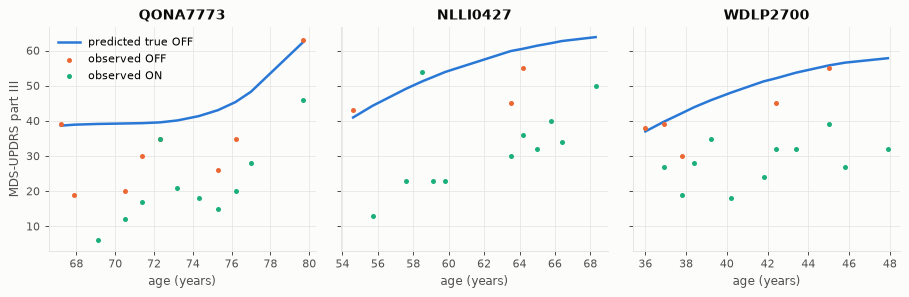

In [12]:
# Figure 3 — three test patients: the predicted trajectory next to the scores they carry.
counts = X_test_f.groupby(PATIENT).size()
candidates = counts[counts >= 6].index.to_numpy()
if len(candidates) < 3:
    candidates = counts.sort_values(ascending=False).index.to_numpy()
chosen = np.random.default_rng(0).choice(candidates, size=3, replace=False)

test_view = X_test_f.assign(prediction=predictions.to_numpy())
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.4), sharey=True)
for ax, patient in zip(axes, chosen):
    frame = test_view[test_view[PATIENT] == patient].sort_values("age")
    ax.plot(frame["age"], frame["prediction"], color=style.PRED_COLOR, linewidth=2,
            label="predicted true OFF")
    observed_off = frame[frame["off"].notna()]
    ax.scatter(observed_off["age"], observed_off["off"], s=16, linewidths=0,
               color=style.ORANGE, label="observed OFF", zorder=3)
    observed_on = frame[frame["on"].notna()]
    ax.scatter(observed_on["age"], observed_on["on"], s=16, linewidths=0,
               color=style.GREEN, label="observed ON", zorder=3)
    ax.set_title(str(patient))
    ax.set_xlabel("age (years)")
axes[0].set_ylabel("MDS-UPDRS part III")
axes[0].legend(loc="best")
fig.tight_layout()

## 6. How the model was chosen

**The protocol.**

- **Folds are whole patients.** A patient's visits lie on one smooth curve, so a visit-level
  split would let the model interpolate a patient it has already seen.
- **Selection on 85% of the patients; the other 15% read at most once.** The holdout was frozen
  before the late decisions; each configuration may be scored on it once, and every read is
  logged.
- **Comparisons are paired and pooled.** Re-running an identical model with another booster seed
  moves a single-seed comparison by −0.0593 but a three-seed pooled one by only −0.0040, so
  candidates are compared with a patient-level paired bootstrap pooled over three CV seeds.
- **Search and confirmation are kept apart.** In the last rounds, ideas were tried on a search
  half of the development patients and re-measured once on an untouched confirmation half,
  under a decision rule written down before the numbers were read.

**The path.** Each row is a configuration that was kept. MSE by 5-fold CV on all training
patients, on the holdout, and on the public leaderboard; "—" means not measured.

| configuration | what it added | CV | holdout | public |
|---|---|---|---|---|
| additive | features from additively de-biased scores (the clinical literature's prior) | 18.30 | — | 17.17 |
| structural | the multiplicative observation model: features on the ratio scale | 11.98 | — | 11.48¹ |
| structural + PK | the per-patient ON response; the envelope fitted near the upper edge | 9.04 | — | — |
| consolidated | an age axis for patients without a diagnosis date; the likelihood step; five-seed booster average | 7.4146 | 7.5025 | 6.0459 |
| v3 | neighbouring visits; per-patient smoothing | 6.7517 | 6.8958 | 5.4696 |
| v4 | ON-amplitude prior from (age at diagnosis, sex); running lower bound | 5.9811 | 6.0086 | 4.9193 |
| v6 | learned lower bounds; absorption delay and effect loading | 5.2016 | 5.5323 | 4.4824 |
| v7 | scale test-time augmentation; a set transformer (weight 0.2) | 5.0263 | 5.2570 | 4.3728 |
| v8 | GRU set models; level-normalised boosters | 4.9690 | 5.1308 | 4.3521 |
| v9 | the two lower-bound switches of section 3 | — | — | 4.1982 |
| v10 | blend re-weighted; pre-trained GRUs; cubic smoothing | — | — | 4.1579 |
| **v11** | **the generator's ×1.02 continuation on the fitted curve** | — | — | **4.1202** |

¹ Scored by a probe copy of the structural chain, not by the run its CV comes from.

Up to v6 the gains came from the features. A pre-registered check then asked whether the
incumbent's remaining errors could still be predicted from the features. On held-out patients
they could not: correcting each of three probed error pockets made the score worse (+0.0159,
+0.0313, +0.0563). The feature chain was frozen there, and every later gain came from how the
learner uses the same information.

v7 passed its holdout rule. v8 improved the holdout (5.2570 → 5.1308) but its interval did not
exclude zero, as the rule required. v9 to v11 were too small for a single holdout read to
resolve (calibrated chances of passing 0.113, 0.129 and 0.135, against the 0.5 the protocol
asks for), so their holdout was never read. All four were adopted on the development evidence
as documented deviations from the protocol: v8 after its holdout read, v9 to v11 under adoption
rules fixed before their numbers were read. For v11 against v10 the paired difference is
−0.0367 [−0.0514, −0.0223] over all development patients and −0.0355 on the untouched
confirmation patients, and the gain sits where the rule acts: on the visits the generator grew
by ×1.02 the error falls by 0.4151 per visit, while the cubic-driven ones are left alone
(+0.0008).

In [13]:
# The headline cross-validation number. Off by default: it refits the whole chain in every fold,
# which is where most of an hour goes.
if RUN_CV:
    from pdchallenge.evaluation.cv import cross_validate

    with timed("cross-validation"):
        result = cross_validate(
            cfg.features,
            with_seed(model_spec, cfg.model_seed),
            X_train,
            y,
            X_train[PATIENT].to_numpy(),
            n_splits=2 if SMOKE else cfg.n_splits,
            seed=cfg.cv_seed,
            tta_scales=cfg.tta_scales,
        )
    print(f"out-of-fold MSE {result.summary['mse']:.4f}")
    print(f"  between patients {result.summary['between_patient']:.3f} "
          f"· within patients {result.summary['within_patient']:.3f}")
else:
    print("cross-validation skipped — set PD_NB_RUN_CV=1 to run it:")
    print(f"  {cfg.n_splits} folds grouped by patient over the full training set, rebuilding the")
    print("  whole chain inside every fold; on the order of an hour on this cohort.")
    print("  With PD_NB_SMOKE=1 it is two folds on the subsample instead.")
    print("  v11 has no full-set cross-validation number: it was adopted on the pooled")
    print("  development comparison of section 6, not on a CV reading.")

cross-validation skipped — set PD_NB_RUN_CV=1 to run it:
  5 folds grouped by patient over the full training set, rebuilding the
  whole chain inside every fold; on the order of an hour on this cohort.
  With PD_NB_SMOKE=1 it is two folds on the subsample instead.
  v11 has no full-set cross-validation number: it was adopted on the pooled
  development comparison of section 6, not on a CV reading.


## 7. Limitations

- **Transductive within a patient.** The `neighbour` step and the smoothing let a visit use the
  patient's other visits, including later ones. That matches the task, where a test visit comes
  with the rest of its trajectory, but it is not a forecast: predicting a patient's later visits
  from their first k alone gives 27.1771 at k = 3 and 28.7105 at k = 5 (measured on the v6 chain).
- **The top of the scale is under-predicted.** An MSE-optimal model shrinks extreme values toward
  the centre, and the patients with the highest true scores carry the largest bias.
- **Byte-for-byte reproduction needs the same platform.** With the pinned versions on the machine
  that wrote our upload (Apple silicon, macOS) the file matches exactly. Elsewhere the boosters
  and the GRUs can differ in the last digits, which section 5 then reports through the summary
  statistics. The GRUs' thread count is fixed in the configuration (`threads: 1`) for the same
  reason.

In [14]:
# Where the time went. `START` was set in section 1, so this covers the work from there on.
print(pd.DataFrame(
    [{"step": label, "seconds": round(seconds, 1)} for label, seconds in TIMINGS.items()]
).to_string(index=False))
total = time.perf_counter() - START
print(f"\ntotal {total:.1f} s ({total / 60:.1f} min)")

                                step  seconds
                         data · load      0.1
       chain · fit_transform (train)     60.7
           chain · transform derived      0.0
            chain · transform debias      0.0
     chain · transform patient_curve      0.1
          chain · transform on_ratio      0.0
       chain · transform pk_response      5.7
chain · transform patient_aggregates      0.3
    chain · transform envelope_curve      0.6
        chain · transform likelihood      1.4
         chain · transform neighbour      0.1
             chain · transform floor      0.0
              chain · transform edge      1.0
                         model · fit   1543.4
                     model · predict    308.5

total 1924.0 s (32.1 min)
